In [ ]:
import bs4
import lxml
import pandas
import urllib
import time

from urllib import request

In [ ]:
#CHARGER LE FICHIER bdd_finale.csv
from google.colab import files

uploaded = files.upload()

for fn in uploaded.keys():
  print('User uploaded file "{name}" with length {length} bytes'.format(
      name=fn, length=len(uploaded[fn])))

Saving bdd_finale.csv to bdd_finale.csv
User uploaded file "bdd_finale.csv" with length 3613741 bytes


In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("bdd_finale.csv")

# Aperçu initial
print("Aperçu des données avant nettoyage :")
display(df[["Prix", "Note", "Avis"]].head())


# Nettoyage de la variable Prix
df["Prix"] = (
    df["Prix"]
    .astype(str)
    .str.replace("€", "", regex=False)
    .str.replace(",", ".", regex=False)
    .str.strip()
)

df["Prix"] = pd.to_numeric(df["Prix"], errors="coerce")

# supprimer les prix négatifs
df.loc[df["Prix"] < 0, "Prix"] = np.nan


# Nettoyage de la variable Note
df["Note"] = (
    df["Note"]
    .astype(str)
    .str.replace(",", ".", regex=False)
)

df["Note"] = pd.to_numeric(df["Note"], errors="coerce")

# Suppression des valeurs en dehors de l'intervalle [0, 5]
df.loc[df["Note"] > 5, "Note"] = np.nan
df.loc[df["Note"] < 0, "Note"] = np.nan


# Nettoyage de la variable Avis
df["Avis"] = (
    df["Avis"]
    .astype(str)
    .str.replace("(", "", regex=False)
    .str.replace(")", "", regex=False)
    .str.replace("+", "", regex=False)
    .str.strip()
)

df["Avis"] = pd.to_numeric(df["Avis"], errors="coerce")

# Supprimer les avis négatifs
df.loc[df["Avis"] < 0, "Avis"] = np.nan

# Résumé après nettoyage
print("\nRésumé statistique après nettoyage :")
display(df[["Prix", "Note", "Avis"]].describe())

print("\nValeurs manquantes après nettoyage :")
display(df[["Prix", "Note", "Avis"]].isna().mean() * 100)

# Sauvegarde du dataset nettoyé (optionnel)
df.to_csv("bdd_finale_clean.csv", index=False)
print("\nFichier 'bdd_finale_clean.csv' sauvegardé.")

Aperçu des données avant nettoyage :


,Prix,Note,Avis
0,22,"4,5",(440+)
1,18,"4,5",(440+)
2,22,"4,5",(440+)
3,16,"4,5",(440+)
4,18,"4,5",(440+)



Résumé statistique après nettoyage :


,Prix,Note,Avis
count,14122.000000,11373.000000,9092.000000
mean,13.513979,4.382652,247.449516
std,8.741116,0.407033,257.302194
min,0.000000,1.300000,2.000000
25%,7.500000,4.200000,30.000000
50%,13.000000,4.500000,130.000000
75%,16.500000,4.600000,430.000000
max,161.000000,4.900000,900.000000



Valeurs manquantes après nettoyage :


,0
Prix,0.021239
Note,19.483186
Avis,35.631858



Fichier 'bdd_finale_clean.csv' sauvegardé.


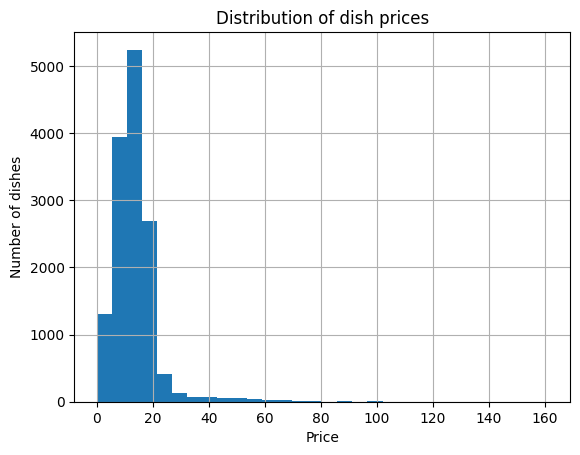

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Chargement des données
df = pd.read_csv("bdd_finale_clean.csv")

df.head()


plt.figure()
df["Prix"].dropna().hist(bins=30)
plt.title("Distribution of dish prices")
plt.xlabel("Price")
plt.ylabel("Number of dishes")
plt.show()








In [ ]:
price_by_category = (
    df.groupby("Catégorie fixée")["Prix"]
      .agg(["mean", "median", "count"])
      .sort_values("mean", ascending=False)
)

price_by_category

,mean,median,count
Catégorie fixée,,,
Pâtes - IT,15.763038,15.9,1514
Pâtes - Asie,14.085484,14.3,620
Pizzas,13.847954,13.9,3646
Burger,12.969698,12.9,2052
Sushis,12.900272,7.9,6290


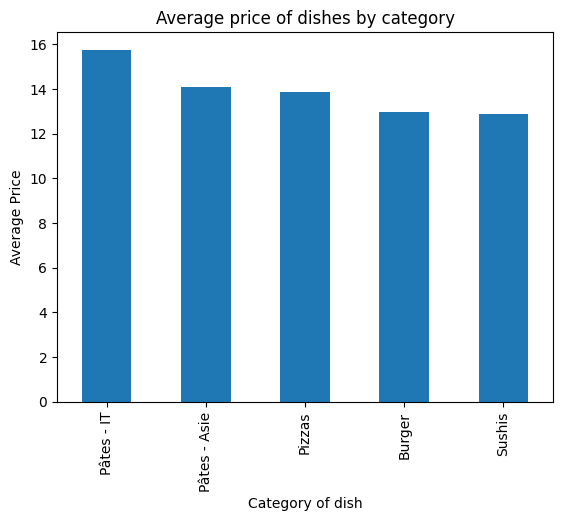

In [ ]:
plt.figure()
price_by_category["mean"].plot(kind="bar")
plt.title("Average price of dishes by category")
plt.xlabel("Category of dish")
plt.ylabel("Average Price")
plt.show()

In [ ]:
# Extraction de l’arrondissement depuis le code postal
df["Arrondissement"] = df["Code postal"].astype(str).str[-2:]

price_by_arr = (
    df.groupby("Arrondissement")["Prix"]
      .agg(["mean", "median", "count"])
      .sort_index()
)

price_by_arr

,mean,median,count
Arrondissement,,,
01,13.078453,11.95,543
02,12.972349,12.00,630
03,12.702163,12.90,416
04,14.754082,13.90,98
05,13.927023,14.50,477
06,14.244610,14.00,269
07,13.803521,15.00,426
08,14.271984,13.25,620
09,12.917924,12.50,1055


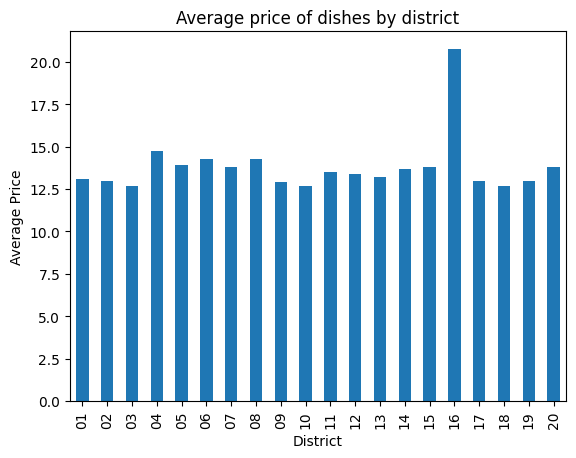

In [ ]:
plt.figure()
price_by_arr["mean"].plot(kind="bar")
plt.title("Average price of dishes by district")
plt.xlabel("District")
plt.ylabel("Average Price")
plt.show()

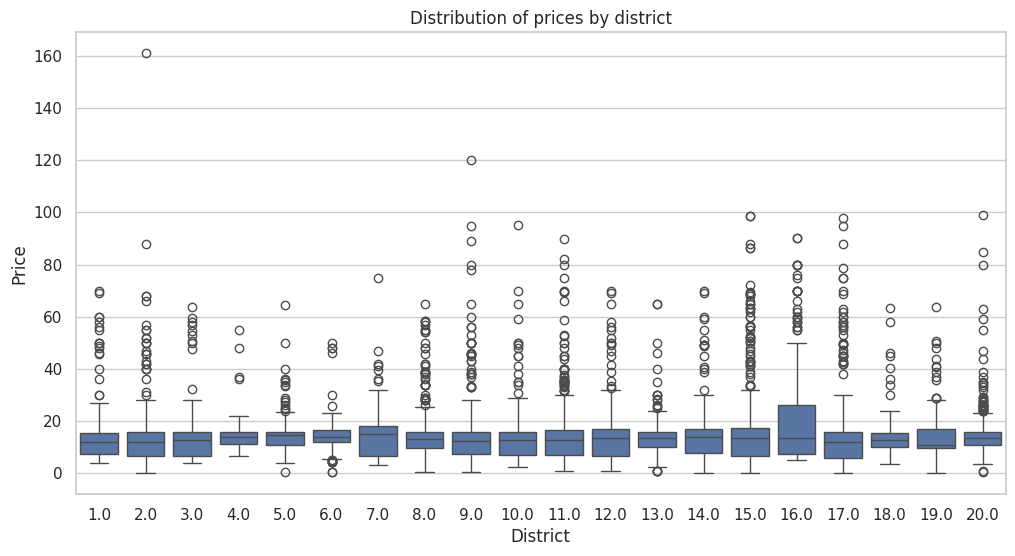

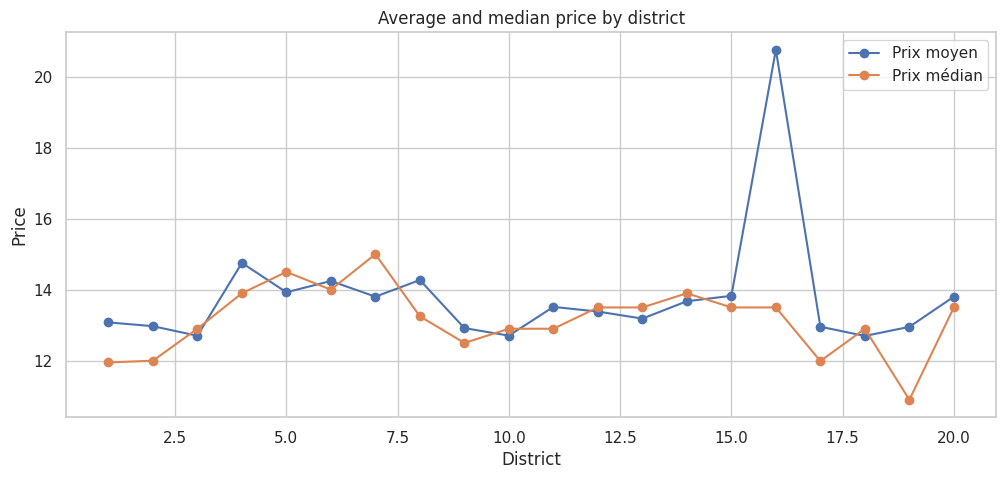

In [ ]:
df["Arrondissement"] = (
    df["Code postal"]
    .astype(str)
    .str[2:]
    .astype(float)
)


plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df,
    x="Arrondissement",
    y="Prix"
)
plt.title("Distribution of prices by district")
plt.xlabel("District")
plt.ylabel("Price")
plt.show()

# Prix moyen et médian par arrondissement
prix_arr = (
    df.groupby("Arrondissement")["Prix"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

plt.figure(figsize=(12, 5))
plt.plot(prix_arr["Arrondissement"], prix_arr["mean"], marker="o", label="Prix moyen")
plt.plot(prix_arr["Arrondissement"], prix_arr["median"], marker="o", label="Prix médian")
plt.legend()
plt.title("Average and median price by district")
plt.xlabel("District")
plt.ylabel("Price")
plt.show()

In [ ]:
price_by_pricecat = (
    df.groupby("Prix catégorie")["Prix"]
      .agg(["mean", "median", "count"])
)

price_by_pricecat

,mean,median,count
Prix catégorie,,,
$,13.743175,13.9,1197
$$,13.283851,12.9,9489


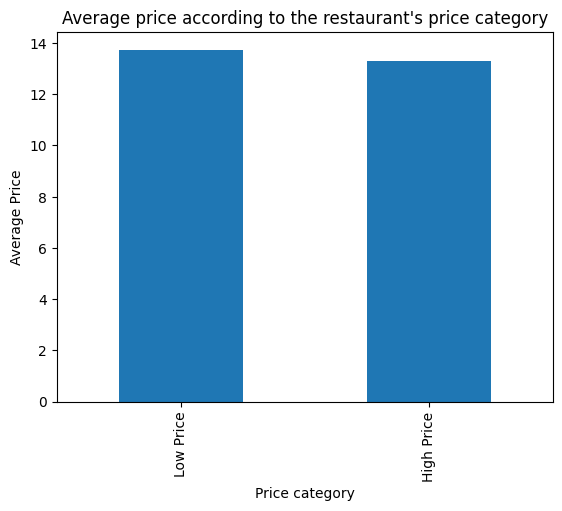

In [ ]:
price_by_pricecat = (
    df.groupby("Prix catégorie")["Prix"]
      .agg(["mean", "median", "count"])
)

price_by_pricecat

price_by_pricecat_plot = price_by_pricecat.copy()
price_by_pricecat_plot.index = price_by_pricecat_plot.index.map({
    '$': 'Low Price',
    '$$': 'High Price'
})

plt.figure()
price_by_pricecat_plot["mean"].plot(kind="bar")
plt.title("Average price according to the restaurant's price category")
plt.xlabel("Price category")
plt.ylabel("Average Price")
plt.show()

In [ ]:
price_by_category = (
    df.groupby("Prix catégorie")["Prix"]
      .agg(["mean", "median", "count"])
      .sort_values("mean", ascending=False)
)

price_by_category

,mean,median,count
Prix catégorie,,,
$,13.743175,13.9,1197
$$,13.283851,12.9,9489


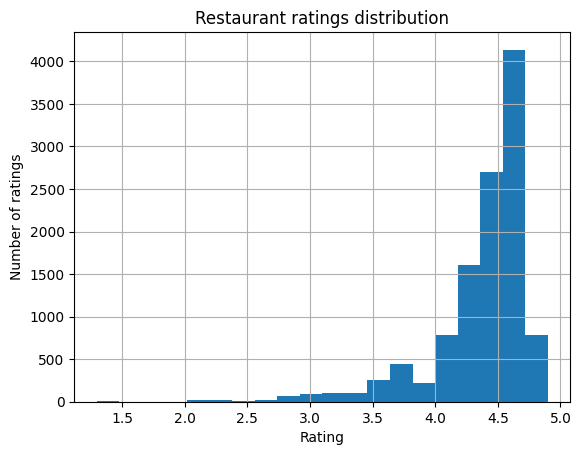

In [ ]:
plt.figure()
df["Note"].dropna().hist(bins=20)
plt.title("Restaurant ratings distribution")
plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.show()

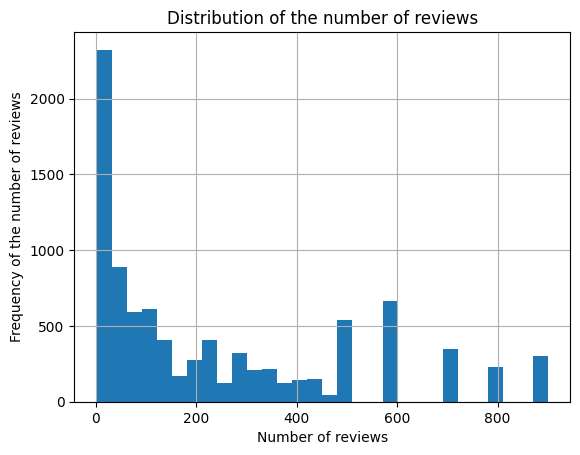

In [ ]:
plt.figure()
df["Avis"].dropna().hist(bins=30)
plt.title("Distribution of the number of reviews")
plt.xlabel("Number of reviews")
plt.ylabel("Frequency of the number of reviews")
plt.show()

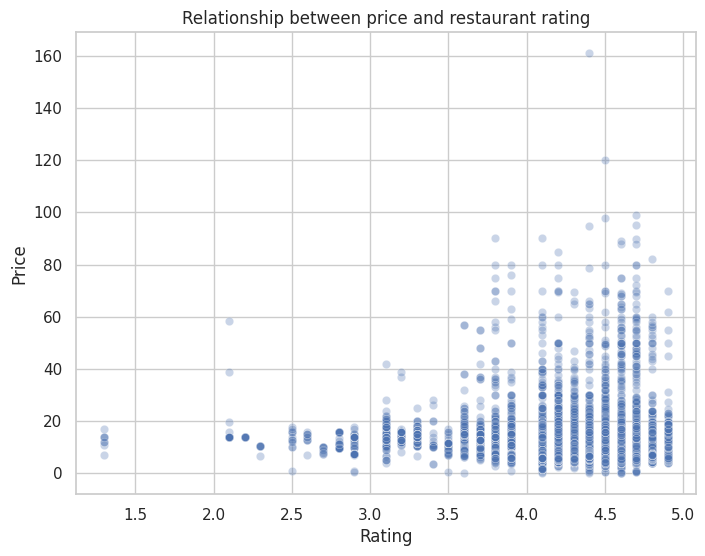

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

df = pd.read_csv("bdd_finale_clean.csv")

# Création de l'arrondissement
df["Arrondissement"] = (
    df["Code postal"]
    .astype(str)
    .str[:-2]
    .astype(float)
)

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x="Note",
    y="Prix",
    alpha=0.3
)
plt.title("Relationship between price and restaurant rating")
plt.xlabel("Rating")
plt.ylabel("Price")
plt.show()



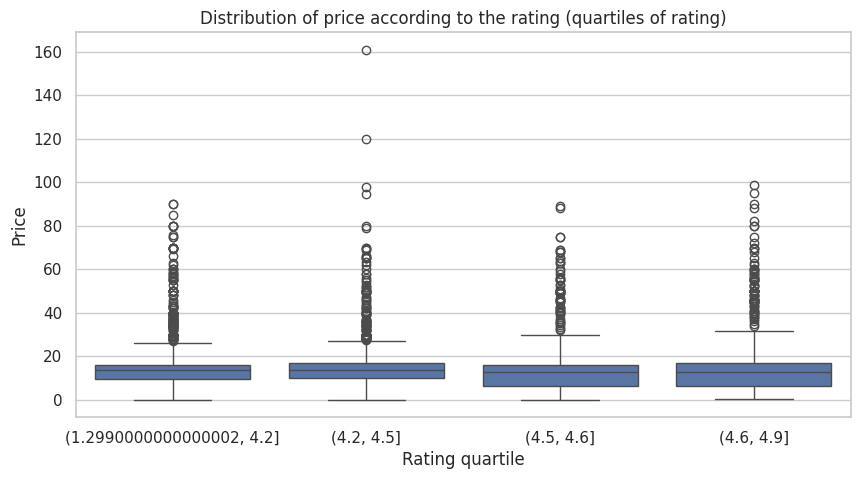

In [ ]:
import seaborn as sns

df["Quartile_Note"] = pd.qcut(df["Note"], q=4, duplicates="drop")

plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x="Quartile_Note",
    y="Prix"
)
plt.title("Distribution of price according to the rating (quartiles of rating)")
plt.xlabel("Rating quartile")
plt.ylabel("Price")
plt.show()

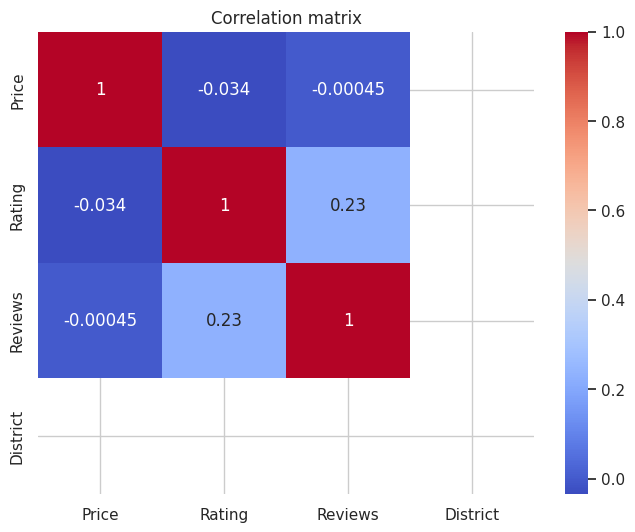

             Price    Rating   Reviews  District
Price     1.000000 -0.034239 -0.000451       NaN
Rating   -0.034239  1.000000  0.228505       NaN
Reviews  -0.000451  0.228505  1.000000       NaN
District       NaN       NaN       NaN       NaN


In [ ]:
#Transformation des colonnes en anglais
df["Price"] = df["Prix"]
df["Rating"] = df["Note"]
df["Reviews"] = df["Avis"]
df["District"] = df["Arrondissement"]



corr = df[["Price", "Rating", "Reviews", "District"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation matrix")
plt.show()
print(corr)

In [ ]:
#TELECHARGER LE FICHIER
from google.colab import files
files.download("bdd_finale_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>